# 01 · Exploratory analysis of 2.5 years of store-day sales

**Summary.** Of 1,017,209 raw store-days, 844,338 open days with sales remain. Closed days are mostly Sundays and
public holidays, and 54 zero-sales open days are dropped as errors. 180 stores are missing from the file for July-December
2014; that gap sits outside every 2015 test window used in notebook 02. The store alone explains 57% of the variance in
log sales, and store x weekday x promotion explains 86%. Demand runs on three clocks:
* the week: footfall swings 30% from Monday to Saturday;
* the payday cycle: about +5% at the turn of the month and −7% in the fourth week, on quiet days;
* Christmas: December is about +20%.

Trading days next to a public holiday jump by up to 22%. Promotions lift sales 38.6% on the raw weekday-matched view
(traffic +19.6%, ticket +15.7%). But they are network-wide, run in whole weeks and favour the first and third weeks of
the month, so a causal estimate needs time fixed effects and week-clustered errors (notebook 03). Stores with a
competitor under 500 m sell *more*, because competitors open in busy places, so pricing a competitor needs an event
study, not a cross-section. After removing the weekday x promo profile, the leftover autocorrelation decays slowly over
six weeks. At a six-week horizon that supports the ETL's recent-level feature rather than lags. Every published figure
checked here matches: 844,338 rows, the 180-store gap, LFL +3.3%, the +30% footfall swing and the promotion uplifts.

Data: Rossmann Store Sales (Kaggle competition, 2015), 1,115 German drugstores, Jan 2013 - Jul 2015. The licence does not
allow redistribution, so this notebook shows profiles and aggregates only, never raw rows.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "4")   # share the laptop: other projects run at the same time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
from IPython.display import display
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42


def fig_title(fig, title, subtitle=None):
    """Insight title and method subtitle for a multi-panel figure."""
    h = fig.get_figheight()
    fig.suptitle(title, x=0.01, y=1 - 0.04 / h, ha="left", va="top", fontsize=14, fontweight="bold", color=PALETTE["ink"])
    if subtitle:
        fig.text(0.01, 1 - 0.36 / h, subtitle, ha="left", va="top", fontsize=10, color="#5A6478")
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.50 if subtitle else 0.30) / h), pad=0.6)


# Numbers already published in the Power BI report, README and data/model_metrics.csv
PUBLISHED = {"rows_raw": 1_017_209, "open_store_days": 844_338, "stores_with_h2_2014_gap": 180, "lfl_2015": 0.033,
             "weekday_footfall_swing": 0.30}

## 1. Business understanding

Two questions share this data. The first is operational: **how much will each store sell on each of the next 42 days?**
Store managers set staff rosters and order stock weeks ahead, so the forecast is made on a Friday for the next six weeks
(the Kaggle horizon, also used in `etl/build_data.py`). The second is commercial: **what do promotions and new
competitors really do to sales?** That needs causal methods, not a forecast, and is answered in notebook 03.

| Item | Decision |
|---|---|
| Decision served | Staff hours and stock per store-day, set six weeks ahead; promotion planning; response to a new competitor |
| Unit of analysis | Store-day (open days only; a closed store has no demand to staff for) |
| Target | Daily net sales in EUR; customers (transactions) as the footfall proxy |
| Horizon and window | Forecast origin = cut-off date, horizon 1-43 days; history Jan 2013 to the cut-off |
| Information at forecast time | Store attributes, the promotion calendar, public and school holidays, planned openings. No sales after the cut-off |
| Success metric | RMSPE (the competition metric) and MAPE per store-day; network bias for stock; error in staff hours (notebook 02) |
| Money value | Each euro of forecast error becomes over- or under-staffing; notebook 02 converts error into staff hours |
| Constraints | Six-week horizon rules out lag-1 style features; data cannot be redistributed; 180 stores miss half a year |

## 2. Data audit

Load the three source files with the same code the ETL uses (`features.py` mirrors `etl/build_data.py`), then check
shape, keys, types and ranges before trusting any chart.

In [2]:
tr, stores, fact, X0 = F.build_frame(ROOT)
raw_store = pd.read_csv(ROOT / ".raw" / "rossmann" / "store.csv")
assert len(tr) == PUBLISHED["rows_raw"] and tr["Store"].nunique() == 1115
print(f"train: {len(tr):,} store-days, {tr['Store'].nunique():,} stores, {tr['Date'].min():%d %b %Y} to {tr['Date'].max():%d %b %Y}")
display(audit.profile(tr))
print(audit.duplicates(tr, key=["Store", "Date"]))

train: 1,017,209 store-days, 1,115 stores, 01 Jan 2013 to 31 Jul 2015


,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
Store,int64,1017209,0.0000,1115,1,558.0000,1115,NaN,0.0000
DayOfWeek,int64,1017209,0.0000,7,1,4.0000,7,NaN,0.0000
Date,datetime64[us],1017209,0.0000,942,2013-01-01 00:00:00,NaN,2015-07-31 00:00:00,2015-07-31,NaN
Sales,int64,1017209,0.0000,21734,0,"5,744.0000",41551,NaN,16.9900
Customers,int64,1017209,0.0000,4086,0,609.0000,7388,NaN,16.9900
Open,int64,1017209,0.0000,2,0,1.0000,1,NaN,16.9900
Promo,int64,1017209,0.0000,2,0,0.0000,1,NaN,61.8500
StateHoliday,str,1017209,0.0000,4,None,NaN,None,0,NaN
SchoolHoliday,int64,1017209,0.0000,2,0,0.0000,1,NaN,82.1400


{'rows': 1017209, 'exact_duplicate_rows': 0, 'duplicate_keys': 0}


One row per store and date, no exact duplicates, no missing values in the daily file. The day-of-week column agrees with
the date (checked below). The work is in the zero rows and in the gaps.

In [3]:
assert (tr["DayOfWeek"] == tr["Date"].dt.day_of_week + 1).all()
acc = pd.Series({
    "raw store-days": len(tr),
    "closed (Open = 0)": int((tr["Open"] == 0).sum()),
    "closed but with sales > 0": int(((tr["Open"] == 0) & (tr["Sales"] > 0)).sum()),
    "open with zero sales": int(((tr["Open"] == 1) & (tr["Sales"] == 0)).sum()),
    "open store-days kept (sales > 0)": len(fact),
}, name="rows").to_frame()
assert len(fact) == PUBLISHED["open_store_days"]
display(acc)
closed = tr[tr["Open"] == 0]
why = pd.Series({
    "Sunday": int((closed["Date"].dt.day_of_week == 6).sum()),
    "public holiday (Mon-Sat)": int(((closed["Date"].dt.day_of_week < 6) & (closed["StateHoliday"] != "0")).sum()),
    "other weekday closure": int(((closed["Date"].dt.day_of_week < 6) & (closed["StateHoliday"] == "0")).sum()),
}, name="closed days")
display(why.to_frame().assign(share=lambda d: d["closed days"] / d["closed days"].sum()))

,rows
raw store-days,1017209
closed (Open = 0),172817
closed but with sales > 0,0
open with zero sales,54
open store-days kept (sales > 0),844338


,closed days,share
Sunday,141137,0.8167
public holiday (Mon-Sat),29833,0.1726
other weekday closure,1847,0.0107


**Cleaning decisions.** Closed days (173K) are dropped: a closed store has no demand to staff for, and the closure itself
is known in advance. The 54 open days with zero sales are dropped as recording errors (the ETL does the same, and RMSPE
is undefined at zero). Most closures are Sundays and holidays; the rest are store-specific. Long weekday closures are
usually refurbishments, and they matter for forecasting because sales jump when a store reopens:

In [4]:
long_runs = F.closure_spells(tr, min_days=5)
print(f"{len(long_runs)} weekday closures of 5+ days in {long_runs['Store'].nunique()} stores (median {long_runs['days'].median():.0f} days)")
# sales in the 7 days after reopening vs the same store's normal level for that weekday and promo state
norm = np.log(fact["Sales"]) - np.log(fact["Sales"]).groupby([fact["StoreKey"], fact["Date"].dt.day_of_week, fact["Promo"]]).transform("mean")
after = []
for r in long_runs.itertuples():
    m = (fact["StoreKey"] == r.Store) & (fact["Date"] > r.end) & (fact["Date"] <= r.end + pd.Timedelta(days=7))
    after.append(norm[m].mean())
print(f"first week after reopening: sales {np.expm1(np.nanmean(after)):+.1%} vs the store's normal level (mean of {np.sum(~np.isnan(after))} reopenings)")

87 weekday closures of 5+ days in 84 stores (median 12 days)


first week after reopening: sales +65.4% vs the store's normal level (mean of 85 reopenings)


### The 180-store gap

The README warns that 180 stores have no data for July-December 2014. Count it directly and see what it does to the
number of trading stores:

stores in the file per day: 935 to 1115; gap stores return on 01 Jan 2015


,StoreType,Assortment
gap,,
False,"{'a': 0.55, 'd': 0.29, 'c': 0.14, 'b': 0.02}","{'a': 0.51, 'c': 0.48, 'b': 0.01}"
True,"{'a': 0.47, 'd': 0.45, 'c': 0.08, 'b': 0.01}","{'a': 0.64, 'c': 0.36, 'b': 0.01}"


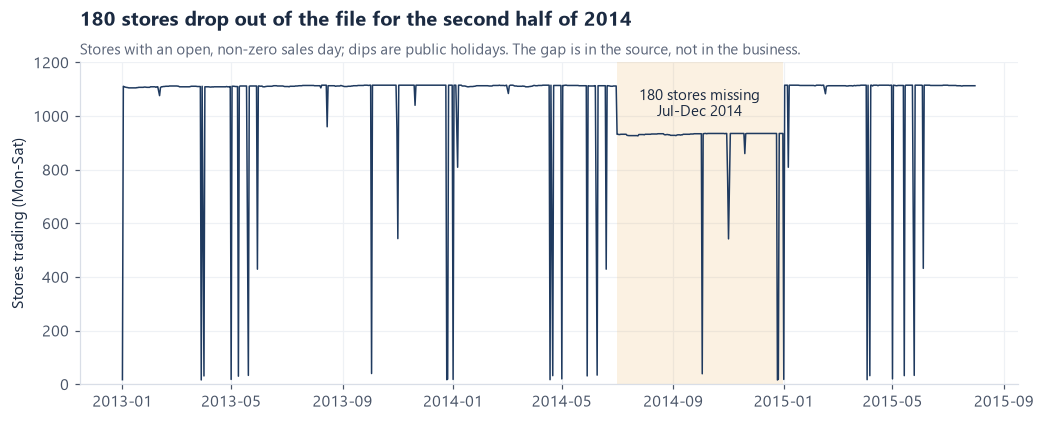

In [5]:
h2 = tr[(tr["Date"] >= "2014-07-01") & (tr["Date"] <= "2014-12-31")].groupby("Store").size()
gap_stores = sorted(set(tr["Store"]) - set(h2.index))
assert len(gap_stores) == PUBLISHED["stores_with_h2_2014_gap"]
per_day = tr.groupby("Date")["Store"].nunique()
print(f"stores in the file per day: {per_day.min()} to {per_day.max()}; gap stores return on {tr[tr['Store'].isin(gap_stores) & (tr['Date'] > '2014-07-01')]['Date'].min():%d %b %Y}")
gap_attr = stores.assign(gap=stores["Store"].isin(gap_stores)).groupby("gap")[["StoreType", "Assortment"]].agg(lambda s: s.value_counts(normalize=True).round(2).to_dict())
display(gap_attr)

fig, ax = plt.subplots(figsize=(11, 3.8))
trading = fact.groupby("Date")["StoreKey"].nunique()
mon_sat = trading[trading.index.day_of_week < 6]
ax.plot(mon_sat.index, mon_sat.values, color=PALETTE["navy"], lw=1)
ax.axvspan(pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31"), color=PALETTE["amber"], alpha=0.15, lw=0)
ax.text(pd.Timestamp("2014-09-30"), 1000, "180 stores missing\nJul-Dec 2014", ha="center", fontsize=9.5, color=PALETTE["ink"])
ax.set_ylim(0, 1200); ax.set_ylabel("Stores trading (Mon-Sat)"); ax.set_xlabel("")
headline(ax, "180 stores drop out of the file for the second half of 2014",
         "Stores with an open, non-zero sales day; dips are public holidays. The gap is in the source, not in the business.")
savefig(fig, "01-coverage", FIG); plt.show()

The gap stores are a fair mix of formats (table above), so the gap is a data-collection issue rather than closures. It
affects three things downstream: like-for-like comparisons (the report only compares store-months present in both
years), store encodings (built on fewer days for these stores) and event windows in notebook 03 (events need enough
pre- and post-days). It does **not** touch the forecast test windows, which are all in 2015.

### Store file: missing fields and how they are imputed

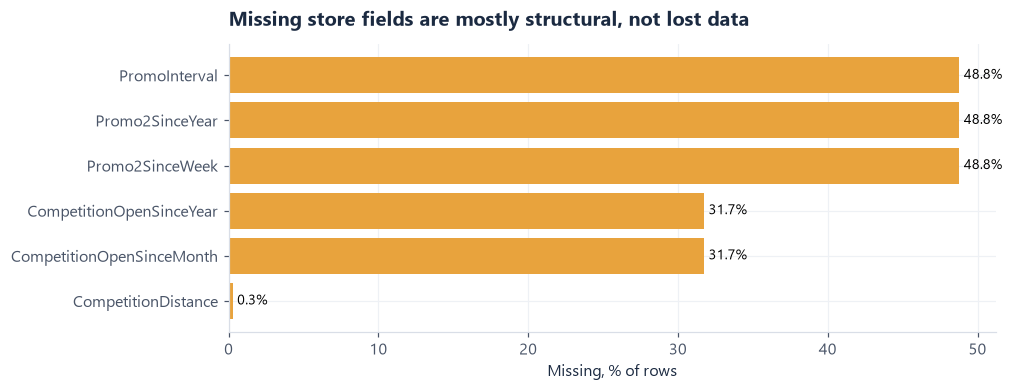

Promo2 fields missing exactly when the store is not in the loyalty promotion (544 stores): structural.
Competitor opening date missing for 354 stores; 351 of them do have a competitor distance (a competitor exists, its opening date was not recorded).
Competitor distance missing: 3 stores. Opening year 1900 (a sentinel for 'long ago'): 1 store(s).
Competitor distance (m): {'count': 1112.0, 'mean': 5405.0, 'std': 7663.0, 'min': 20.0, '10%': 250.0, '50%': 2325.0, '90%': 15679.0, 'max': 75860.0}


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
audit.plot_missing(raw_store, ax=ax, title="Missing store fields are mostly structural, not lost data")
plt.show()
p2 = raw_store["Promo2"] == 0
assert raw_store.loc[p2, ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().all().all()
assert raw_store.loc[~p2, ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].notna().all().all()
no_date_but_distance = int((raw_store["CompetitionOpenSinceYear"].isna() & raw_store["CompetitionDistance"].notna()).sum())
print(f"Promo2 fields missing exactly when the store is not in the loyalty promotion ({p2.sum()} stores): structural.")
print(f"Competitor opening date missing for {raw_store['CompetitionOpenSinceYear'].isna().sum()} stores; "
      f"{no_date_but_distance} of them do have a competitor distance (a competitor exists, its opening date was not recorded).")
print(f"Competitor distance missing: {raw_store['CompetitionDistance'].isna().sum()} stores. "
      f"Opening year 1900 (a sentinel for 'long ago'): {(raw_store['CompetitionOpenSinceYear'] == 1900).sum()} store(s).")
print("Competitor distance (m):", raw_store["CompetitionDistance"].describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_dict())

| Field | Missing | Meaning | Treatment (ETL and model) |
|---|---|---|---|
| Promo2SinceWeek / Year, PromoInterval | 544 stores | Store not in the loyalty promotion | Loyalty month = 0; no imputation needed |
| CompetitionOpenSinceMonth / Year | 354 stores | Competitor exists (351) but opening date unknown | `comp_months = -1` ("unknown"), kept as its own value for the trees |
| CompetitionDistance | 3 stores | No competitor recorded | 100 km, i.e. "far away" |
| CompetitionOpenSinceYear = 1900 | 1 store | Sentinel for "long ago" | Competitor age capped at 240 months |

None of these is imputed with a mean: each missing value has a business meaning, and trees can use it directly.

### Outliers

A robust z-score per store-day against the store's own weekday-and-promo norm (median and MAD on log sales) finds the
unusual days. The question is whether they are errors to remove or demand to model.

In [7]:
ls = np.log(fact["Sales"])
grp = [fact["StoreKey"], fact["Date"].dt.day_of_week, fact["Promo"]]
med = ls.groupby(grp).transform("median")
mad = (ls - med).abs().groupby(grp).transform("median") * 1.4826
z = (ls - med) / mad.replace(0, np.nan)
out = fact.assign(z=z)[z.abs() > 3.5]
print(f"{len(out):,} store-days ({len(out) / len(fact):.2%}) are more than 3.5 robust SDs from their store's norm; "
      f"{(out['z'] > 0).mean():.0%} of them are highs")
top_dates = out.groupby("Date").size().sort_values(ascending=False).head(8).rename("stores with an outlier")
display(top_dates.to_frame().assign(weekday=lambda d: d.index.day_name(),
                                    state_holiday_next_3_days=lambda d: [bool(X0.loc[X0["Date"] == t, "days_to_hol"].min() <= 3) for t in d.index]))

19,297 store-days (2.29%) are more than 3.5 robust SDs from their store's norm; 80% of them are highs


,stores with an outlier,weekday,state_holiday_next_3_days
Date,,,
2013-12-23,1047,Monday,True
2014-12-23,850,Tuesday,True
2014-12-22,816,Monday,True
2013-12-21,654,Saturday,False
2013-12-30,590,Monday,True
2013-12-20,569,Friday,False
2013-12-16,433,Monday,False
2013-03-30,422,Saturday,True


The extreme days cluster on dates such as Christmas Eve week and the trading days next to public holidays, when many
stores spike together. That is real demand (shoppers stock up before a closure), so the outliers stay in. The model
needs "days to the next holiday" and "days since the last one" to explain them, which the ETL already provides.

## 3. Sales distribution and store heterogeneity

In [8]:
store_lvl = fact.groupby("StoreKey").agg(sales=("Sales", "mean"), customers=("Customers", "mean"), days=("Sales", "size"))
store_lvl["ticket"] = fact.groupby("StoreKey")["Sales"].sum() / fact.groupby("StoreKey")["Customers"].sum()
store_lvl = store_lvl.join(stores.set_index("Store")[["StoreType", "Assortment", "CompetitionDistance", "Promo2"]])
q = store_lvl["sales"].quantile([0.1, 0.5, 0.9])
print(f"Daily sales per open store-day: mean EUR {fact['Sales'].mean():,.0f}, median EUR {fact['Sales'].median():,.0f}, "
      f"skew {fact['Sales'].skew():.2f}; log sales skew {np.log(fact['Sales']).skew():.2f}")
print(f"Store averages: P10 EUR {q[0.1]:,.0f}, median EUR {q[0.5]:,.0f}, P90 EUR {q[0.9]:,.0f} (P90/P10 = {q[0.9] / q[0.1]:.1f}x)")
# how much of the variation in log sales is between stores vs within a store?
tot = ls.var()
within_store = (ls - ls.groupby(fact["StoreKey"]).transform("mean")).var()
within_profile = (ls - ls.groupby(grp).transform("mean")).var()
print(f"Share of log-sales variance explained by the store alone: {1 - within_store / tot:.0%}; "
      f"by store x weekday x promo: {1 - within_profile / tot:.0%}")

by_type = fact.merge(stores[["Store", "StoreType", "Assortment"]], left_on="StoreKey", right_on="Store")
type_tab = by_type.groupby("StoreType").agg(stores=("StoreKey", "nunique"), sales_per_day=("Sales", "mean"), customers_per_day=("Customers", "mean"),
                                            sunday_share=("Date", lambda s: (s.dt.day_of_week == 6).mean()))
type_tab["ticket"] = by_type.groupby("StoreType")["Sales"].sum() / by_type.groupby("StoreType")["Customers"].sum()
display(type_tab.round(3))
display(by_type.groupby("Assortment").agg(stores=("StoreKey", "nunique"), sales_per_day=("Sales", "mean"), customers_per_day=("Customers", "mean")).round(0))

Daily sales per open store-day: mean EUR 6,956, median EUR 6,369, skew 1.59; log sales skew -0.11
Store averages: P10 EUR 4,527, median EUR 6,590, P90 EUR 9,677 (P90/P10 = 2.1x)


Share of log-sales variance explained by the store alone: 57%; by store x weekday x promo: 86%


,stores,sales_per_day,customers_per_day,sunday_share,ticket
StoreType,,,,,
a,602,"6,925.6980",795.4220,0.0020,8.7070
b,17,"10,233.3800","2,022.2120",0.1420,5.0600
c,148,"6,933.1260",815.5380,0.0000,8.5010
d,348,"6,822.3000",606.3540,0.0010,11.2510


,stores,sales_per_day,customers_per_day
Assortment,,,
a,593,"6,622.0000",748.0000
b,9,"8,643.0000","2,068.0000"
c,513,"7,301.0000",752.0000


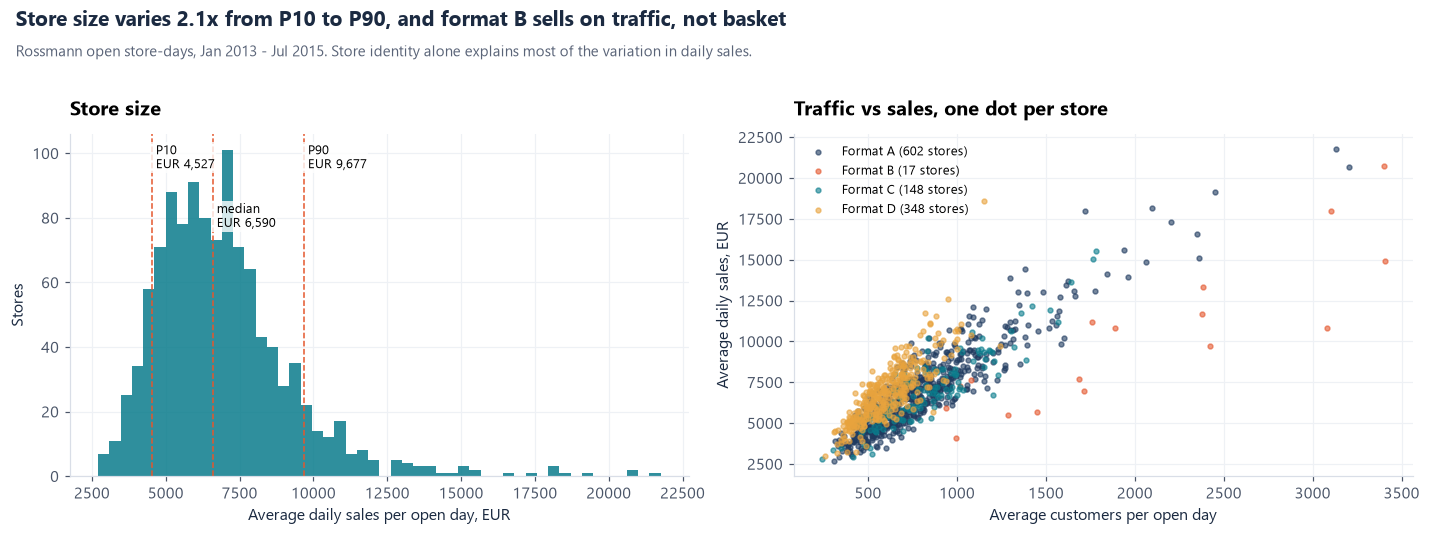

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.hist(store_lvl["sales"], bins=50, color=PALETTE["teal"], alpha=0.85)
for qq, lab, yy in ((0.1, "P10", 0.97), (0.5, "median", 0.80), (0.9, "P90", 0.97)):
    a1.axvline(q[qq], color=PALETTE["coral"], lw=1, ls="--")
    a1.text(q[qq], a1.get_ylim()[1] * yy, f" {lab}\n EUR {q[qq]:,.0f}", fontsize=8.5, va="top",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
a1.set(xlabel="Average daily sales per open day, EUR", ylabel="Stores", title="Store size")
colors = {"a": PALETTE["navy"], "b": PALETTE["coral"], "c": PALETTE["teal"], "d": PALETTE["amber"]}
for t, g in store_lvl.groupby("StoreType"):
    a2.scatter(g["customers"], g["sales"], s=10, alpha=0.6, color=colors[t], label=f"Format {t.upper()} ({len(g)} stores)")
a2.set(xlabel="Average customers per open day", ylabel="Average daily sales, EUR", title="Traffic vs sales, one dot per store")
a2.legend(fontsize=8.5)
fig_title(fig, f"Store size varies {q[0.9] / q[0.1]:.1f}x from P10 to P90, and format B sells on traffic, not basket",
          "Rossmann open store-days, Jan 2013 - Jul 2015. Store identity alone explains most of the variation in daily sales.")
plt.show()

Daily sales are right-skewed; on the log scale they are close to symmetric. Two choices follow. The model is fitted on
log sales, which matches RMSPE (a relative-error metric) and stops the large stores from dominating the loss. And the
store's own level (its target encoding) has to be a feature: the store alone explains most of the variance in log sales.
Format B (17 stores) is a different business: most customers per day, the lowest ticket, and it trades on Sundays.

## 4. Seasonality: weekday, payday, month and holidays

Store mix changes from day to day (Sundays have 33 trading stores; H2 2014 lacks 180), so raw daily averages mislead.
Every profile below is **composition-adjusted**: log sales minus the store's own mean, then averaged. A value of +0.10
means "10% above that store's normal day" (approximately).

Footfall per store-day, Monday-Saturday: peak Mon 855, trough Sat 660: a +30% swing (published: +30%)
Same swing composition-adjusted (each store vs its own mean): +34%


Day of month (quiet days only): days 28-3 +4.7%, days 21-26 -6.7% vs the store x weekday x promo norm


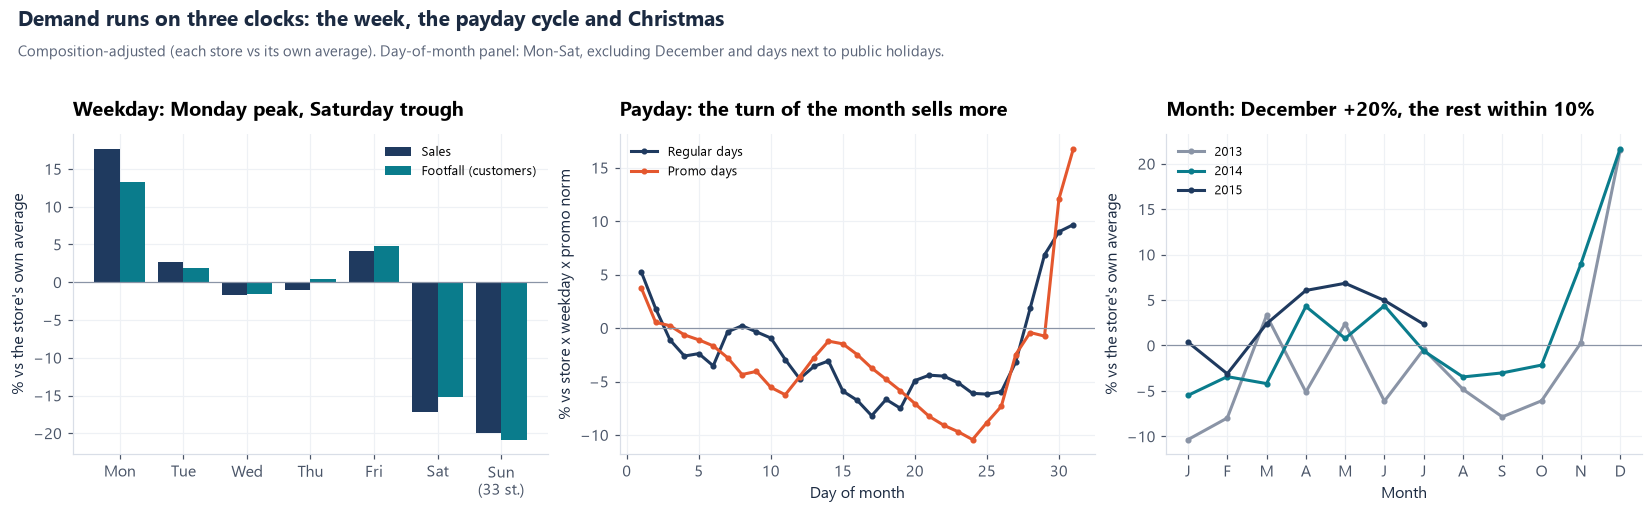

In [10]:
f = fact.copy()
f["ls"] = np.log(f["Sales"])
f["adj"] = f["ls"] - f.groupby("StoreKey")["ls"].transform("mean")
f["adj_profile"] = f["ls"] - f.groupby(["StoreKey", f["Date"].dt.day_of_week, "Promo"])["ls"].transform("mean")
f["adj_c"] = np.log(f["Customers"].clip(lower=1)) - np.log(f["Customers"].clip(lower=1)).groupby(f["StoreKey"]).transform("mean")
f["dow"], f["dom"], f["month"], f["year"] = f["Date"].dt.day_of_week, f["Date"].dt.day, f["Date"].dt.month, f["Date"].dt.year
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = f.groupby("dow").agg(sales=("adj", "mean"), footfall=("adj_c", "mean"), stores=("StoreKey", "nunique"))
cust = fact.assign(dow=fact["Date"].dt.day_of_week).groupby("dow")["Customers"].mean()
swing = cust.loc[:5].max() / cust.loc[:5].min() - 1          # the report's definition: raw customers per store-day, Mon-Sat
print(f"Footfall per store-day, Monday-Saturday: peak {DOW[cust.loc[:5].idxmax()]} {cust.loc[:5].max():,.0f}, "
      f"trough {DOW[cust.loc[:5].idxmin()]} {cust.loc[:5].min():,.0f}: a {swing:+.0%} swing (published: +30%)")
assert abs(swing - PUBLISHED["weekday_footfall_swing"]) < 0.01
adj_swing = np.exp(wd["footfall"].loc[:5].max() - wd["footfall"].loc[:5].min()) - 1
print(f"Same swing composition-adjusted (each store vs its own mean): {adj_swing:+.0%}")
# day of month: leave out December and days next to a public holiday so pre-holiday shopping does not pose as payday
quiet = (X0["days_to_hol"].to_numpy() > 3) & (X0["days_since_hol"].to_numpy() > 2) & (f["month"].to_numpy() != 12) & (f["dow"].to_numpy() < 6)
dom_prof = f[quiet].groupby(["dom", "Promo"])["adj_profile"].mean().unstack()
dom_all = f[quiet].groupby("dom")["adj_profile"].mean()
turn = np.expm1(dom_all.loc[[28, 29, 30, 31, 1, 2, 3]].mean()); fourth = np.expm1(dom_all.loc[21:26].mean())
print(f"Day of month (quiet days only): days 28-3 {turn:+.1%}, days 21-26 {fourth:+.1%} vs the store x weekday x promo norm")
mon_prof = f[f["dow"] < 6].groupby(["month", "year"])["adj"].mean().unstack()

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.6))
a1.bar(np.arange(7) - 0.2, np.expm1(wd["sales"]) * 100, width=0.4, color=PALETTE["navy"], label="Sales")
a1.bar(np.arange(7) + 0.2, np.expm1(wd["footfall"]) * 100, width=0.4, color=PALETTE["teal"], label="Footfall (customers)")
a1.axhline(0, color=PALETTE["grey"], lw=0.8)
a1.set_xticks(range(7), [f"{d}\n({n} st.)" if d == "Sun" else d for d, n in zip(DOW, wd["stores"])])
a1.set(ylabel="% vs the store's own average", title="Weekday: Monday peak, Saturday trough")
a1.legend(fontsize=8.5)
a2.plot(dom_prof.index, np.expm1(dom_prof[0]) * 100, color=PALETTE["navy"], marker="o", ms=3, label="Regular days")
a2.plot(dom_prof.index, np.expm1(dom_prof[1]) * 100, color=PALETTE["coral"], marker="o", ms=3, label="Promo days")
a2.axhline(0, color=PALETTE["grey"], lw=0.8)
a2.set(xlabel="Day of month", ylabel="% vs store x weekday x promo norm", title="Payday: the turn of the month sells more")
a2.legend(fontsize=8.5)
for y, c in zip(mon_prof.columns, [PALETTE["grey"], PALETTE["teal"], PALETTE["navy"]]):
    a3.plot(mon_prof.index, np.expm1(mon_prof[y]) * 100, marker="o", ms=3, color=c, label=str(y))
a3.axhline(0, color=PALETTE["grey"], lw=0.8)
a3.set_xticks(range(1, 13), list("JFMAMJJASOND"))
a3.set(xlabel="Month", ylabel="% vs the store's own average", title="Month: December +20%, the rest within 10%")
a3.legend(fontsize=8.5)
fig_title(fig, "Demand runs on three clocks: the week, the payday cycle and Christmas",
          "Composition-adjusted (each store vs its own average). Day-of-month panel: Mon-Sat, excluding December and days next to public holidays.")
savefig(fig, "01-seasonality", FIG); plt.show()

* **Weekday.** Monday is the busiest day and Saturday the quietest among Monday-Saturday. Raw footfall swings by the
  published +30% (the composition-adjusted swing is printed above), so staffing to the weekly average under-staffs
  Mondays and over-staffs Saturdays. The few Sunday stores sell below their own weekday norm.
* **Payday.** German salaries are paid at the end of the month. Even on quiet days (no holiday nearby, no December) and
  after removing weekday and promotion, the turn of the month sells above the store norm and the fourth week below it.
  Day of month is a real feature, and it matters for notebook 03 because promotions are not spread evenly over the month.
* **Month.** December stands out; the other months stay within about 10% of normal and the three years overlap, so the
  annual cycle is stable enough for month and day-of-year features to learn it.

### Like-for-like growth (parity with the report)

In [11]:
sm = fact.assign(ym=fact["Date"].dt.to_period("M")).groupby(["StoreKey", "ym"])["Sales"].sum()
cur = sm[sm.index.get_level_values("ym").year == 2015]
ly = sm.reindex(pd.MultiIndex.from_arrays([cur.index.get_level_values(0), cur.index.get_level_values(1) - 12]))
ly.index = cur.index
both = (cur > 0) & (ly.fillna(0) > 0)
lfl = cur[both].sum() / ly[both].sum() - 1
print(f"Like-for-like sales growth, Jan-Jul 2015 vs Jan-Jul 2014 (same store-months): {lfl:+.1%} (published: +3.3%)")
assert abs(lfl - PUBLISHED["lfl_2015"]) < 0.002

Like-for-like sales growth, Jan-Jul 2015 vs Jan-Jul 2014 (same store-months): +3.3% (published: +3.3%)


### Public holidays: shoppers stock up before a closure

In [12]:
around = []
for k in range(1, 8):
    around.append((-k, f.loc[X0["days_to_hol"].to_numpy() == k, "adj_profile"].mean()))
    around.append((k, f.loc[X0["days_since_hol"].to_numpy() == k, "adj_profile"].mean()))
around = pd.DataFrame(around, columns=["day", "adj"]).sort_values("day")
school = f.groupby(X0["SchoolHoliday"].to_numpy())["adj_profile"].mean()
print("Sales vs normal, by days to (negative) / since (positive) a public holiday:")
print(around.assign(pct=lambda d: np.expm1(d["adj"]).map("{:+.1%}".format))[["day", "pct"]].to_string(index=False))
print(f"School holiday days vs other days: {np.expm1(school[1] - school[0]):+.1%}")

Sales vs normal, by days to (negative) / since (positive) a public holiday:
 day    pct
  -7  +0.5%
  -6  +0.5%
  -5  +3.8%
  -4  +4.2%
  -3  +6.8%
  -2 +18.5%
  -1 +12.9%
   1 +22.0%
   2  +1.9%
   3  +2.4%
   4  +2.5%
   5  -3.2%
   6  -1.1%
   7  -0.9%
School holiday days vs other days: +1.8%


The two trading days before a public holiday sell well above normal (shoppers stock up before the closure) and the first
day after it is the strongest of all (catch-up). By the third day sales are back within a few percent. A plain holiday
flag cannot express this shape; the ETL's `days_to_hol` and `days_since_hol` features can. School holidays move sales
by under 2% once store, weekday and promotion are accounted for.

### STL decomposition of the network series

Seasonal-trend decomposition (STL, robust, weekly period) of the composition-adjusted daily network series separates the
slow trend (including the annual cycle), the weekly pattern and what is left.

Share of variance (components are not orthogonal, so shares need not sum to 1): {'trend': 0.05, 'weekly': 0.39, 'remainder': 0.58}


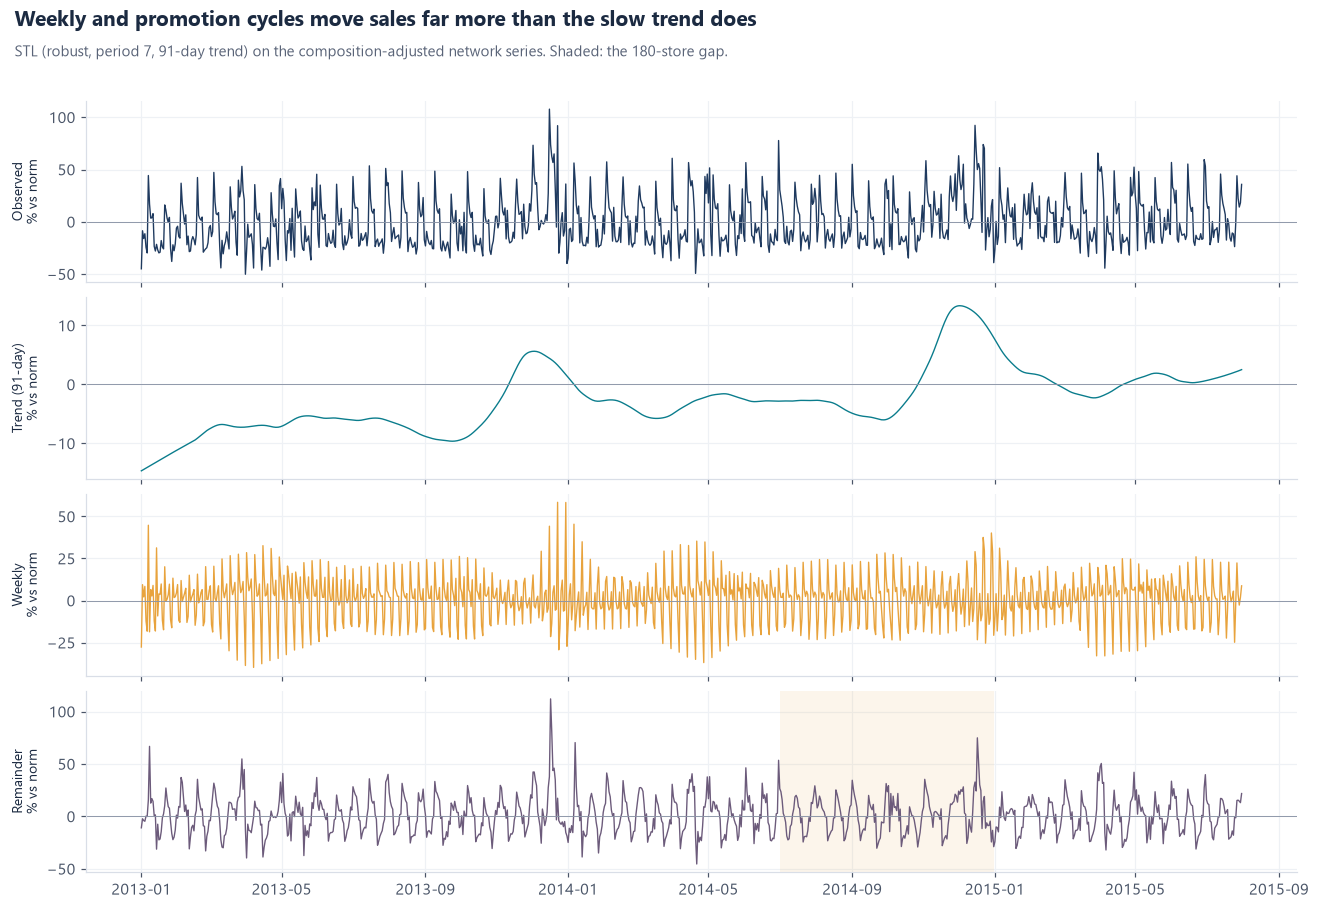

In [13]:
from statsmodels.tsa.seasonal import STL

net = f.groupby("Date")["adj"].mean().asfreq("D")
net_filled = net.interpolate(limit_direction="both")          # closed public holidays: no trading day to average
stl = STL(net_filled, period=7, robust=True, trend=91).fit()
var_share = pd.Series({"trend": stl.trend.var(), "weekly": stl.seasonal.var(), "remainder": stl.resid.var()}) / net_filled.var()
print("Share of variance (components are not orthogonal, so shares need not sum to 1):", var_share.round(2).to_dict())
fig, axes = plt.subplots(4, 1, figsize=(12, 8.2), sharex=True)
for ax, s, lab, c in zip(axes, [net_filled, stl.trend, stl.seasonal, stl.resid], ["Observed", "Trend (91-day)", "Weekly", "Remainder"],
                         [PALETTE["navy"], PALETTE["teal"], PALETTE["amber"], PALETTE["purple"]]):
    ax.plot(s.index, np.expm1(s.values) * 100, color=c, lw=0.9)
    ax.axhline(0, color=PALETTE["grey"], lw=0.6)
    ax.set_ylabel(f"{lab}\n% vs norm", fontsize=9)
axes[-1].axvspan(pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31"), color=PALETTE["amber"], alpha=0.10, lw=0)
fig_title(fig, "Weekly and promotion cycles move sales far more than the slow trend does",
          "STL (robust, period 7, 91-day trend) on the composition-adjusted network series. Shaded: the 180-store gap.")
savefig(fig, "01-stl", FIG); plt.show()

The trend explains about 5% of the day-to-day variance. It drifts up gently (2015 runs 3.3% above 2014 like-for-like)
with a bulge every December, so the model needs a year term and a recent-level feature, not an extrapolated trend line.
The weekly component explains about 40%. The remainder is not noise: it oscillates with a two-week rhythm, the
promotion calendar, which a weekly component cannot absorb. That is why the promotion flag (and its interaction with
store and weekday, `store_dow_promo_mean`) is central to the model.

## 5. Promotions: the raw view

The report's weekday-matched uplift compares promo and regular days on the same weekday (Monday-Friday; promotions never
run at weekends) and averages the five ratios. Reproduce it, then look at **when** promotions run.

In [14]:
mf = fact[fact["Date"].dt.day_of_week < 5].assign(dow=lambda d: d["Date"].dt.day_of_week)
g = mf.groupby(["dow", "Promo"]).agg(sales=("Sales", "sum"), customers=("Customers", "sum"), n=("Sales", "size"))
lift = pd.DataFrame({
    "sales": (g["sales"] / g["n"]).unstack().pipe(lambda t: t[1] / t[0] - 1),
    "traffic": (g["customers"] / g["n"]).unstack().pipe(lambda t: t[1] / t[0] - 1),
    "ticket": (g["sales"] / g["customers"]).unstack().pipe(lambda t: t[1] / t[0] - 1),
})
lift.index = DOW[:5]
display(lift.style.format("{:+.1%}"))
naive = lift.mean()
print(f"Weekday-matched uplift: sales {naive['sales']:+.1%}, traffic {naive['traffic']:+.1%}, ticket {naive['ticket']:+.1%} "
      "(published: +38.6%, +19.6%, +15.7%)")
assert abs(naive["sales"] - 0.386) < 0.001 and abs(naive["traffic"] - 0.196) < 0.001 and abs(naive["ticket"] - 0.157) < 0.001
promo_share_date = fact.groupby("Date")["Promo"].mean()
print(f"Share of dates where promo is all-or-nothing across stores: {promo_share_date.isin([0, 1]).mean():.0%}")
days = fact[fact["Date"].dt.day_of_week < 5].groupby("Date")["Promo"].max().to_frame()
days["dom_band"] = pd.cut(days.index.day, [0, 7, 14, 21, 31], labels=["1-7", "8-14", "15-21", "22-31"])
timing = days.groupby("dom_band", observed=True)["Promo"].mean()
display(timing.rename("share of weekdays with a promotion").to_frame().style.format("{:.0%}"))

,sales,traffic,ticket
Mon,+57.1%,+27.0%,+23.7%
Tue,+44.8%,+22.4%,+18.3%
Wed,+36.8%,+18.8%,+15.1%
Thu,+32.1%,+17.6%,+12.3%
Fri,+22.1%,+12.2%,+8.8%


Weekday-matched uplift: sales +38.6%, traffic +19.6%, ticket +15.7% (published: +38.6%, +19.6%, +15.7%)
Share of dates where promo is all-or-nothing across stores: 100%


,share of weekdays with a promotion
dom_band,
1-7,76%
8-14,34%
15-21,68%
22-31,41%


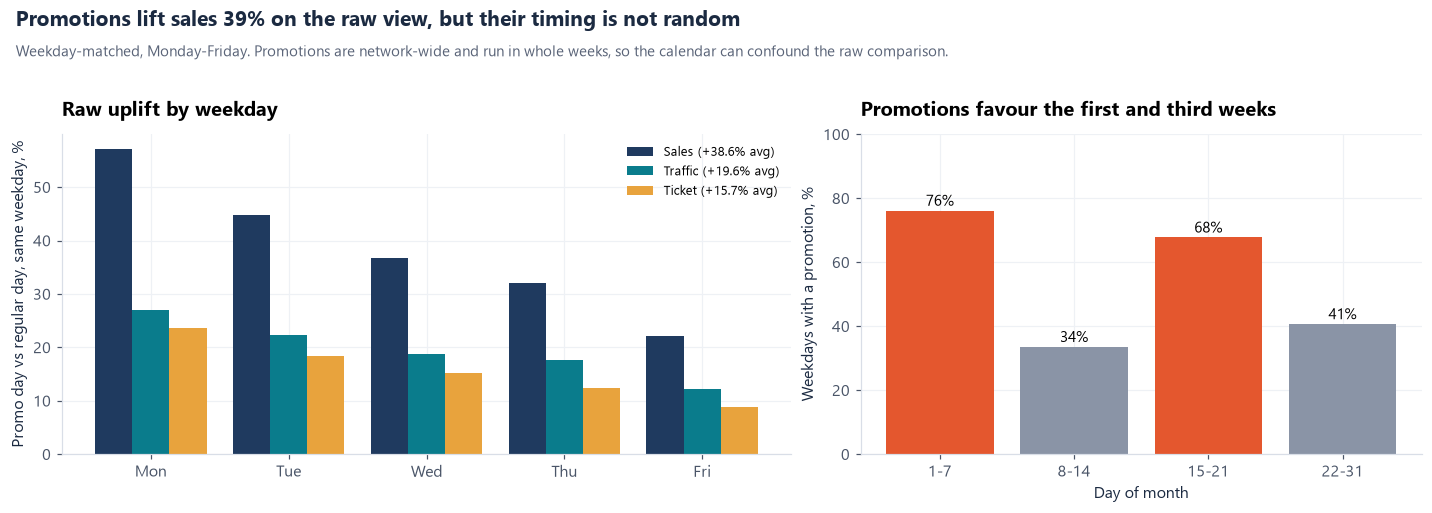

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(5)
for i, (col, c) in enumerate(zip(["sales", "traffic", "ticket"], [PALETTE["navy"], PALETTE["teal"], PALETTE["amber"]])):
    a1.bar(x + (i - 1) * 0.27, lift[col] * 100, width=0.27, color=c, label=f"{col.title()} ({naive[col]:+.1%} avg)")
a1.set_xticks(x, DOW[:5])
a1.set(ylabel="Promo day vs regular day, same weekday, %", title="Raw uplift by weekday")
a1.legend(fontsize=8.5)
a2.bar(timing.index.astype(str), timing.values * 100, color=[PALETTE["coral"] if v > 0.5 else PALETTE["grey"] for v in timing.values])
for i, v in enumerate(timing.values):
    a2.text(i, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=9.5)
a2.set(xlabel="Day of month", ylabel="Weekdays with a promotion, %", title="Promotions favour the first and third weeks", ylim=(0, 100))
fig_title(fig, "Promotions lift sales 39% on the raw view, but their timing is not random",
          "Weekday-matched, Monday-Friday. Promotions are network-wide and run in whole weeks, so the calendar can confound the raw comparison.")
savefig(fig, "01-promo-timing", FIG); plt.show()

Three facts shape notebook 03:

1. **Promotions are network-wide.** On every date either all trading stores are on promotion or none is, and promotions
   run in whole Monday-Friday weeks. There is no control store on the same day, so the effect can only be identified
   over time, and the effective sample is the number of weeks (about 135), not the 844K store-days.
2. **They are timed.** Three quarters of weekdays in the first week of the month carry a promotion, against a third in
   the second week. The first week follows payday and sells more anyway, so part of the raw +38.6% may be timing. A
   fixed-effects model with day-of-month and month controls separates the two.
3. **About half traffic, half basket.** Traffic +19.6% and ticket +15.7% multiply to the +38.6%.
4. **The lift fades through the week**: highest on Monday, lowest on Friday. Either a launch effect or pull-forward
   within the week; notebook 03 also checks for a dip in the week after a promotion.

## 6. Competition distance: a cross-section cannot price a competitor

In [16]:
comp = store_lvl.assign(band=F.competition_band(store_lvl["CompetitionDistance"]))
order = ["Under 0.5 km", "0.5-2 km", "2-5 km", "5-15 km", "15 km+", "Not recorded"]
comp_tab = comp.groupby("band").agg(stores=("sales", "size"), sales_per_day=("sales", "mean"), customers_per_day=("customers", "mean")).reindex(order).dropna()
display(comp_tab.round(0))
rho = store_lvl[["CompetitionDistance", "sales", "customers", "ticket"]].corr(method="spearman").loc["CompetitionDistance"]
print("Spearman correlation of competitor distance with store averages:", rho.drop("CompetitionDistance").round(3).to_dict())

,stores,sales_per_day,customers_per_day
band,,,
Under 0.5 km,218,"7,587.0000",961.0000
0.5-2 km,283,"6,873.0000",797.0000
2-5 km,261,"6,674.0000",687.0000
5-15 km,228,"6,699.0000",622.0000
15 km+,122,"6,948.0000",684.0000
Not recorded,3,"5,368.0000",539.0000


Spearman correlation of competitor distance with store averages: {'sales': -0.028, 'customers': -0.28, 'ticket': 0.474}


Stores with a competitor under 500 m sell **more**, not less. Competitors open where footfall is high (city centres), so
distance is a proxy for location quality. The cross-section mixes "busy place" with "competitor nearby" and cannot say
what a new competitor costs. Notebook 03 uses the timing of competitor openings instead (a difference-in-differences
event study), comparing each store with itself before and after, net of similar stores without an opening.

## 7. Autocorrelation: which memory does the model need?

Two autocorrelation functions, both pooled within store (pairs of days from the same store, Monday-Sunday calendar):
(a) composition-adjusted log sales, and (b) what is left after removing each store's weekday-and-promotion profile.

ACF of adjusted log sales at lags 1, 7, 14, 28: [0.54 0.15 0.63 0.55]
ACF of residual after store x weekday x promo, lags 1, 7, 14, 28, 42: [0.55 0.34 0.24 0.2  0.08]


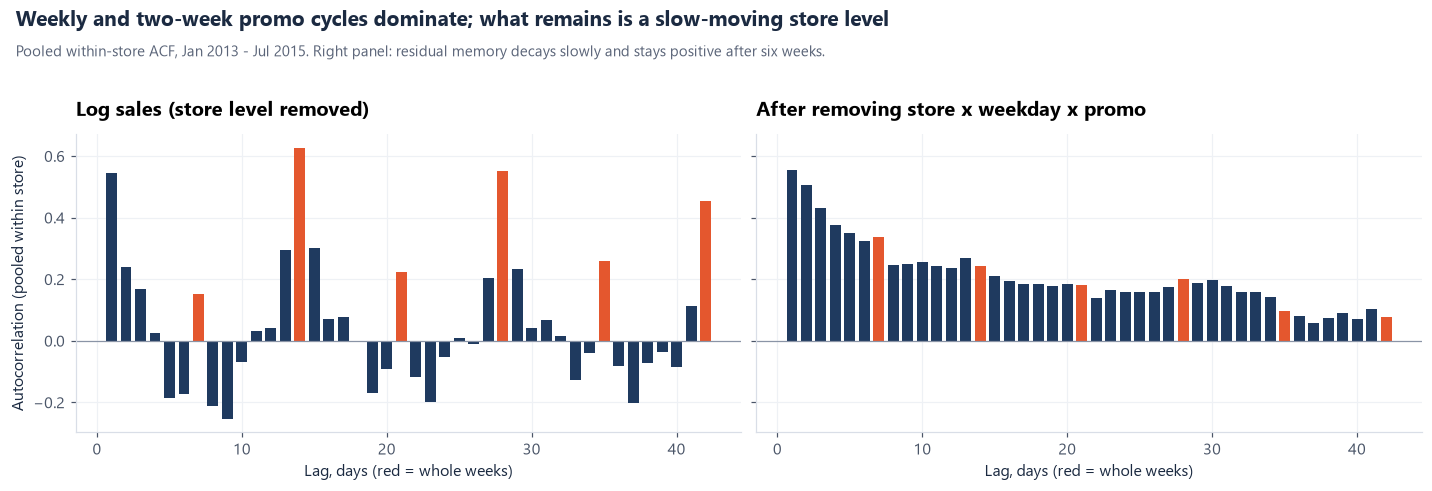

In [17]:
def pooled_acf(values: pd.Series, max_lag: int = 42) -> np.ndarray:
    M = values.unstack("Date").reindex(columns=pd.date_range(fact["Date"].min(), fact["Date"].max(), freq="D")).to_numpy()
    M = M - np.nanmean(M, axis=1, keepdims=True)
    out = []
    for k in range(1, max_lag + 1):
        a, b = M[:, k:], M[:, :-k]
        m = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.sum(a[m] * b[m]) / np.sqrt(np.sum(a[m] ** 2) * np.sum(b[m] ** 2)))
    return np.array(out)

acf_raw = pooled_acf(f.set_index(["StoreKey", "Date"])["adj"])
acf_res = pooled_acf(f.set_index(["StoreKey", "Date"])["adj_profile"])
lags = np.arange(1, 43)
print("ACF of adjusted log sales at lags 1, 7, 14, 28:", acf_raw[[0, 6, 13, 27]].round(2))
print("ACF of residual after store x weekday x promo, lags 1, 7, 14, 28, 42:", acf_res[[0, 6, 13, 27, 41]].round(2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, v, t in ((a1, acf_raw, "Log sales (store level removed)"), (a2, acf_res, "After removing store x weekday x promo")):
    ax.bar(lags, v, color=[PALETTE["coral"] if k % 7 == 0 else PALETTE["navy"] for k in lags], width=0.75)
    ax.axhline(0, color=PALETTE["grey"], lw=0.8)
    ax.set(xlabel="Lag, days (red = whole weeks)", title=t)
a1.set_ylabel("Autocorrelation (pooled within store)")
fig_title(fig, "Weekly and two-week promo cycles dominate; what remains is a slow-moving store level",
          "Pooled within-store ACF, Jan 2013 - Jul 2015. Right panel: residual memory decays slowly and stays positive after six weeks.")
savefig(fig, "01-acf", FIG); plt.show()

* The raw ACF peaks every 7 days and alternates at 14 days: the weekday and the two-week promotion cycle. Both are
  **known in advance**, so they enter the model as calendar and promotion features rather than as lags.
* After removing each store's weekday x promo profile, the residual is still positively autocorrelated and decays
  slowly, staying positive at six weeks. That is a drifting store level (refurbishments, local competition, roadworks).
  A six-week-ahead forecast cannot use yesterday's sales, but it can use the **recent level** of the store: the ETL's
  `recent_shift` (last 8 weeks vs the store's long-run mean) is the right feature for this memory.

## 8. What EDA changed in the plan

* **Model on log sales, evaluate in euros.** Sales are skewed and the metric is relative; the store alone explains most
  of the variance, so store-level encodings (built only from data before the cut-off) are essential.
* **Calendar features carry the seasonality.** Weekday, day of month (payday), December, and days to/from public and
  school holidays. No trend term: the network trend is flat.
* **Use a recent-level feature, not lags.** Residual memory is slow; the eight-week recent shift captures it without
  needing sales the forecaster will not have at a six-week horizon.
* **Backtest in 2015 only.** The 180-store gap sits in H2 2014; the rolling-origin folds (notebook 02) start in February
  2015, so every fold tests the full network.
* **Causal questions need designs, not correlations.** Promotions are network-wide, week-level and payday-timed (fixed
  effects with week-clustered errors); competitor distance is confounded with location (event study on openings).
* **Keep the outliers.** Extreme days are holiday and Christmas demand, not errors; reopenings after refurbishment are a
  known source of forecast error worth flagging to store managers.

In [18]:
report.update_metrics(str(METRICS), "01_eda", {
    "raw_store_days": len(tr), "open_store_days": len(fact), "stores": 1115, "stores_with_h2_2014_gap": len(gap_stores),
    "open_zero_sales_days": int(acc.loc["open with zero sales", "rows"]), "weekday_footfall_swing": swing, "lfl_growth_2015": lfl,
    "promo_uplift_naive": naive["sales"], "promo_traffic_naive": naive["traffic"], "promo_ticket_naive": naive["ticket"],
    "variance_share_store": 1 - within_store / tot, "variance_share_store_dow_promo": 1 - within_profile / tot,
})
print("metrics saved")

metrics saved
